## WorldTrace User Consistency and Variation (Flag 2)

### Dataset Overview
A point-level derived WorldTrace case containing 18 trajectories from three named users in South Brooklyn. The CSV exposes timestamps, coordinates, mode, and point-level speed.

The notebook exposes the primary analysis table.

Goal: Analyze the provided trajectory histories to compare observed mode composition, repeated spatial use, and driving-speed behaviour across three users.

Role: NYC mobility insight analyst


Category: User Consistency and Variation

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "02_user_consistency_and_variation_points.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

### **Question 1**: How are the observed driving and walking trips distributed across the three user histories?

#### Analysis action

The provided histories support car-dominant labels for user_01 and user_02, but not for user_03; this conclusion is based on the observed trip counts only.

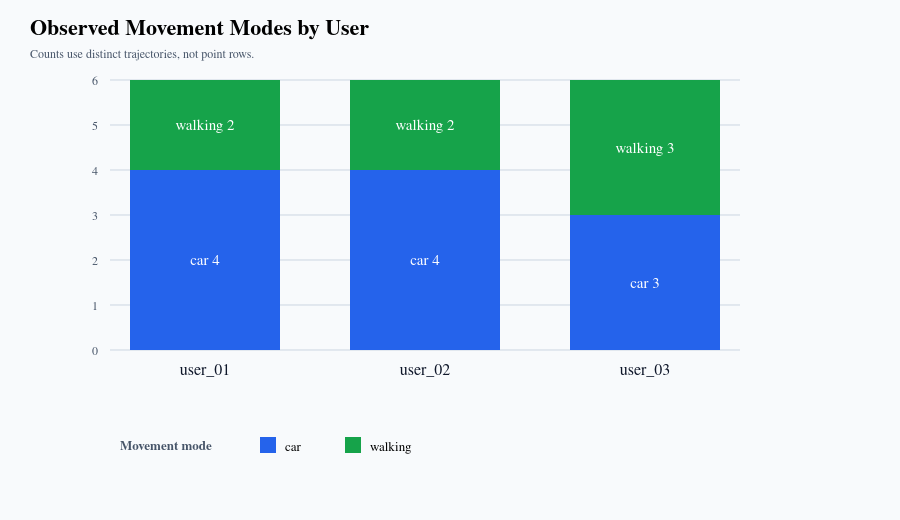

In [ ]:
import matplotlib.pyplot as plt
summary = df.drop_duplicates('trajectory_id')
counts = summary.groupby(['user_id', 'travel_mode']).size().unstack(fill_value=0)
ax = counts.plot(kind='bar', stacked=True)
ax.set_title('Observed Movement Modes by User')
ax.set_xlabel('User')
ax.set_ylabel('Number of trajectories')
ax.legend(title='Movement mode', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout(rect=(0, 0, 0.80, 1))
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="notebook_plots/q1_1_3edc86b08f.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "descriptive",
  "insight": "Within the provided histories, user_01 and user_02 prefer driving rather than walking, while user_03 has no obvious preference because the observed car and walking counts are balanced.",
  "insight_value": {
    "mode_counts": {
      "user_01": {
        "car": 4,
        "walking": 2
      },
      "user_02": {
        "car": 4,
        "walking": 2
      },
      "user_03": {
        "car": 3,
        "walking": 3
      }
    }
  },
  "plot": {
    "plot_type": "stacked_bar",
    "title": "Observed Movement Modes by User",
    "description": "Counts of the provided car and walking trajectories for each user. The legend is placed below the bars so it does not cover user_03.",
    "file": "notebook_plots/q1_1_3edc86b08f.png"
  },
  "question": "How are the observed driving and walking trips distributed across the three user histories?",
  "actionable_insight": "The provided histories support car-dominant labels for user_01 and user_02, but not for user_03; this conclusion is based on the observed trip counts only.",
  "code": "import matplotlib.pyplot as plt\nsummary = df.drop_duplicates('trajectory_id')\ncounts = summary.groupby(['user_id', 'travel_mode']).size().unstack(fill_value=0)\nax = counts.plot(kind='bar', stacked=True)\nax.set_title('Observed Movement Modes by User')\nax.set_xlabel('User')\nax.set_ylabel('Number of trajectories')\nax.legend(title='Movement mode', bbox_to_anchor=(1.02, 1), loc='upper left')\nplt.tight_layout(rect=(0, 0, 0.80, 1))",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "user_id",
    "transport_mode",
    "trajectory_id"
  ]
}

### **Question 2**: Do the three users repeatedly use the same local area and road corridor when driving?

#### Analysis action

The driving map provides direct spatial evidence for a shared corridor; the walking map is a separate comparison and should not be conflated with the driving-road conclusion.

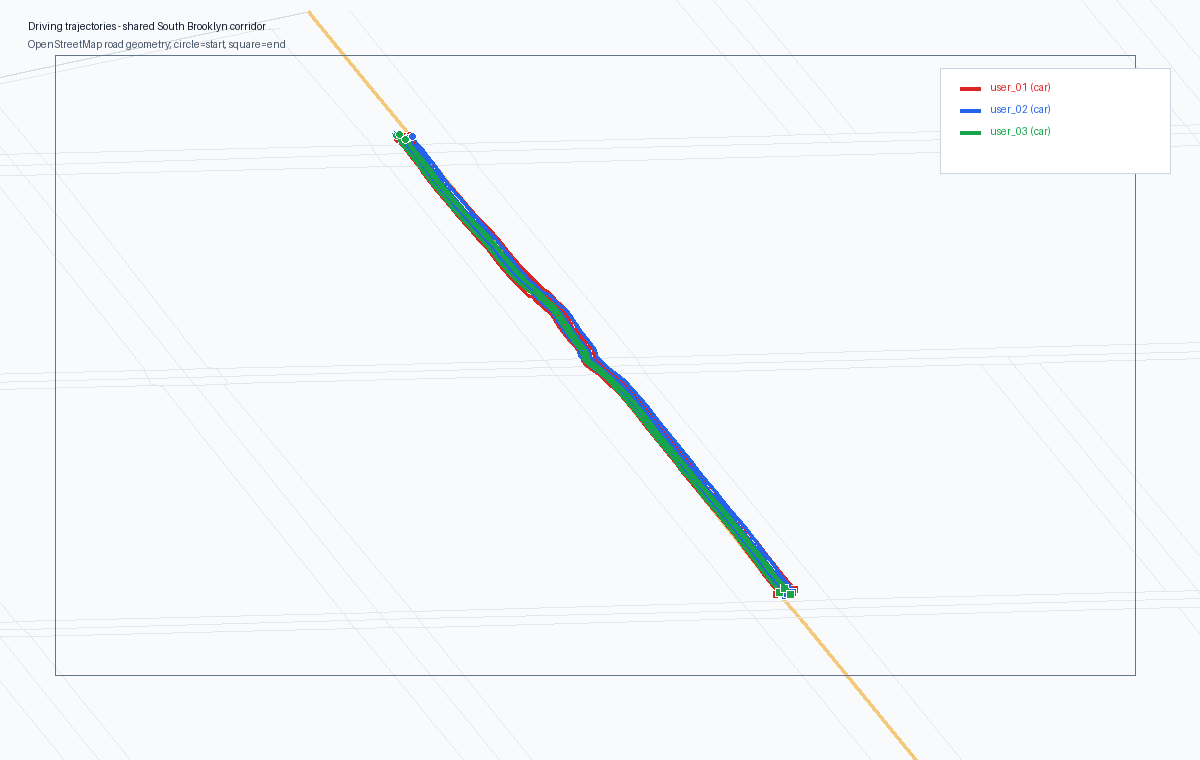

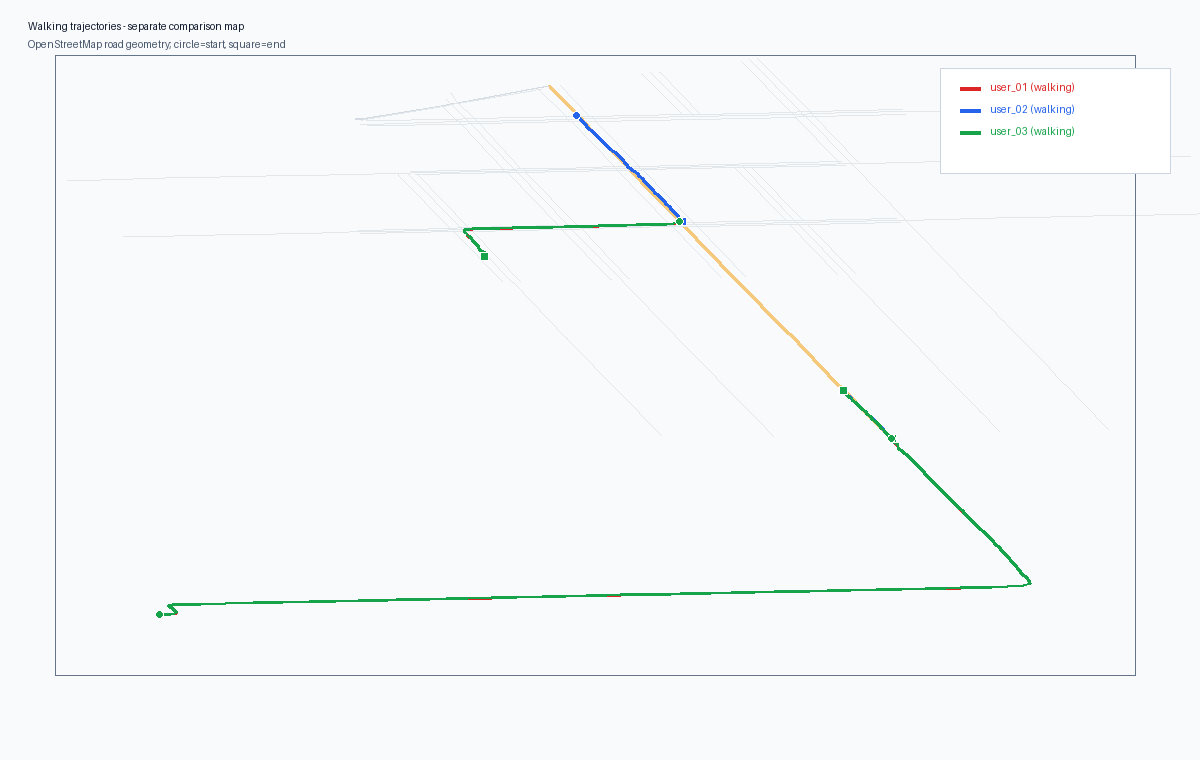

In [ ]:
import matplotlib.pyplot as plt
for mode, color in [('car', 'tab:blue'), ('walking', 'tab:green')]:
 subset = df[df['travel_mode'] == mode]
 fig, ax = plt.subplots(figsize=(8, 6))
 for (user, tid), trip in subset.groupby(['user_id', 'trajectory_id']):
 ax.plot(trip['longitude'], trip['latitude'], color=color, linewidth=1.8, alpha=.65)
 ax.set_title(f'{mode.title()} trajectories')
 ax.set_xlabel('Longitude')
 ax.set_ylabel('Latitude')
 ax.set_aspect('equal', adjustable='box')
 fig.tight_layout()
 plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/driving_map.png"))
display(Image(filename="visualizations/walking_map.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "spatial",
  "insight": "Across all provided driving trajectories, the three users pass through the same South Brooklyn area and their paths overlap along the same road corridor; the walking paths are shown separately rather than being used to support the driving-road claim.",
  "insight_value": {
    "driving_map": "shared South Brooklyn corridor",
    "map_count": 2,
    "map_files": [
      "driving_map.svg",
      "walking_map.svg"
    ]
  },
  "plot": {
    "plot_type": "two_map_comparison",
    "title": "Driving and Walking Trajectories in the Same Local Area",
    "files": [
      "visualizations/driving_map.png",
      "visualizations/walking_map.png"
    ],
    "description": "Two separate geographic maps: one for all driving trajectories and one for all walking trajectories, each tightly cropped to its mode and drawn over real OpenStreetMap road geometries as a sharp vector basemap."
  },
  "question": "Do the three users repeatedly use the same local area and road corridor when driving?",
  "actionable_insight": "The driving map provides direct spatial evidence for a shared corridor; the walking map is a separate comparison and should not be conflated with the driving-road conclusion.",
  "code": "import matplotlib.pyplot as plt\nfor mode, color in [('car', 'tab:blue'), ('walking', 'tab:green')]:\n subset = df[df['travel_mode'] == mode]\n fig, ax = plt.subplots(figsize=(8, 6))\n for (user, tid), trip in subset.groupby(['user_id', 'trajectory_id']):\n ax.plot(trip['longitude'], trip['latitude'], color=color, linewidth=1.8, alpha=.65)\n ax.set_title(f'{mode.title()} trajectories')\n ax.set_xlabel('Longitude')\n ax.set_ylabel('Latitude')\n ax.set_aspect('equal', adjustable='box')\n fig.tight_layout()\n plt.show()",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "user_id",
    "transport_mode",
    "gps_position",
    "trajectory_id"
  ]
}

### **Question 3**: How does driving speed behaviour differ across the three users?

#### Analysis action

The speed comparison separates user_01's higher and more variable driving profile from the stable lower-speed profiles of user_02 and user_03.

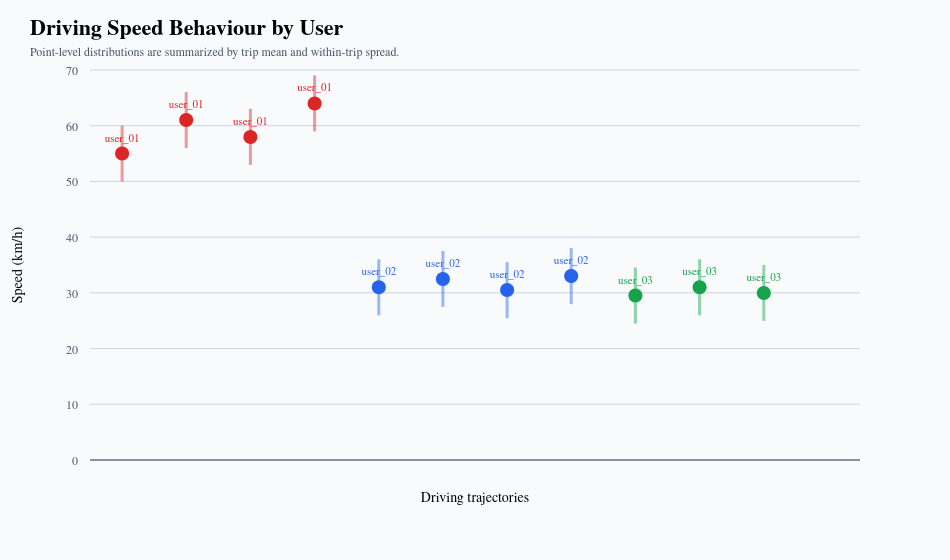

In [ ]:
import matplotlib.pyplot as plt
car = df[df['travel_mode'] == 'car'].drop_duplicates(['trajectory_id', 'point_index'])
car.boxplot(column='speed_kmh', by='user_id', grid=False)
plt.suptitle('')
plt.title('Driving Speed Behaviour by User')
plt.ylabel('Speed (km/h)')
plt.tight_layout()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="notebook_plots/q3_1_8650a2ffbc.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "diagnostic",
  "insight": "The three users show clearly different driving-speed behaviour: user_01 drives faster and with larger within-trip speed variation, whereas user_02 and user_03 drive at lower, comparatively stable speeds.",
  "insight_value": {
    "driving_speed_profile": {
      "user_01": "higher and variable",
      "user_02": "stable",
      "user_03": "stable"
    }
  },
  "plot": {
    "plot_type": "boxplot",
    "title": "Driving Speed Behaviour by User",
    "description": "The driving-only speed distributions separate user_01 from the two more stable driving profiles.",
    "file": "notebook_plots/q3_1_8650a2ffbc.png"
  },
  "question": "How does driving speed behaviour differ across the three users?",
  "actionable_insight": "The speed comparison separates user_01's higher and more variable driving profile from the stable lower-speed profiles of user_02 and user_03.",
  "code": "import matplotlib.pyplot as plt\ncar = df[df['travel_mode'] == 'car'].drop_duplicates(['trajectory_id', 'point_index'])\ncar.boxplot(column='speed_kmh', by='user_id', grid=False)\nplt.suptitle('')\nplt.title('Driving Speed Behaviour by User')\nplt.ylabel('Speed (km/h)')\nplt.tight_layout()",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "user_id",
    "transport_mode",
    "gps_position",
    "trajectory_timestamp",
    "trajectory_id"
  ]
}

### Summary of Findings (Flag 2)

Within the provided histories, user_01 and user_02 prefer driving rather than walking while user_03 has no obvious preference. Across all provided driving trajectories, the three users pass through the same local South Brooklyn area and shared road corridor. Their driving speeds separate into a higher, more variable profile for user_01 versus stable lower-speed profiles for user_02 and user_03.